# Urban Planning PoC — Sentinel‑2 + Landsat‑9 Exploration

This notebook implements **both** complementary spatial views:

1. **Pixel-level unsupervised clustering** on Sentinel‑2 to discover recurring surface regimes.
2. **Regular planning-grid aggregation** so each geographic cell can answer questions such as:
   - What percentage is vegetation-like?
   - Which surface regime dominates?
   - How hot is this area?
   - How much of it is unusually hot?
   - How well does Sentinel‑2 explain its LST?
   - What is its prototype planning priority?

It also trains a supervised Random Forest model to predict Landsat LST from Sentinel‑2-derived features.

The supplied `A-001 ... A-005` polygons are retained as geographic reference, but the modeling and planning outputs are no longer restricted to them.

In [8]:
from pathlib import Path
import xml.etree.ElementTree as ET
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from osgeo import gdal, ogr
from shapely.geometry import box
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import MiniBatchKMeans
from sklearn.model_selection import GroupShuffleSplit
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

gdal.UseExceptions()
RANDOM_STATE = 17
np.random.seed(RANDOM_STATE)
print("GDAL:", gdal.VersionInfo("--version"))


GDAL: GDAL 3.8.4, released 2024/02/08


## 1. Configure paths


In [9]:
DATA_ROOT = Path("./data")
S2_ROOT = DATA_ROOT / "S2C_MSIL2A_20260815T064621_N0512_R020_T40RCN_20260815T114356.SAFE"
LANDSAT_ROOT = DATA_ROOT / "LC09_L2SP_160043_20260815_02_T1"
AOI_GEOJSON = DATA_ROOT / "P2_AOI_A_segme_FeaturesToJSO.geojson"

OUTPUT_DIR = Path("./outputs")
WORK_DIR = OUTPUT_DIR / "_work"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
WORK_DIR.mkdir(parents=True, exist_ok=True)

# The supplied A-001...A-005 polygons are now used only as an anchor/reference.
# We deliberately analyze a much wider surrounding study area.
CONTEXT_BUFFER_M = 3000

# Planning/reporting grid. 250 m gives ~69 Landsat 30 m cells per full grid cell,
# which is a reasonable balance between local detail and stable thermal statistics.
GRID_SIZE_M = 250

N_CLUSTERS = 5
MAX_CLUSTER_TRAIN_PIXELS = 200_000
SPATIAL_BLOCK_M = 300

# Drop grid cells that do not contain enough usable observations.
MIN_VALID_S2_FRACTION = 0.60
MIN_VALID_LST_FRACTION = 0.50

for p in [S2_ROOT, LANDSAT_ROOT, AOI_GEOJSON]:
    print(p, "→", "FOUND" if p.exists() else "MISSING")

data/S2C_MSIL2A_20260815T064621_N0512_R020_T40RCN_20260815T114356.SAFE → FOUND
data/LC09_L2SP_160043_20260815_02_T1 → FOUND
data/P2_AOI_A_segme_FeaturesToJSO.geojson → FOUND


## 2. Geospatial helpers


In [10]:
def find_one(root: Path, pattern: str) -> Path:
    matches = list(root.rglob(pattern))
    if not matches:
        raise FileNotFoundError(f"No file matching {pattern!r} below {root}")
    if len(matches) > 1:
        print(f"Warning: {len(matches)} matches for {pattern}; using {matches[0]}")
    return matches[0]


def raster_info(path):
    ds = gdal.Open(str(path))
    gt = ds.GetGeoTransform()
    b = ds.GetRasterBand(1)
    return {
        "width": ds.RasterXSize,
        "height": ds.RasterYSize,
        "bands": ds.RasterCount,
        "dtype": gdal.GetDataTypeName(b.DataType),
        "nodata": b.GetNoDataValue(),
        "pixel_size_x": gt[1],
        "pixel_size_y": gt[5],
        "projection": ds.GetProjection(),
    }


def read_array(path, dtype=None):
    ds = gdal.Open(str(path), gdal.GA_ReadOnly)

    if ds is None:
        raise RuntimeError(f"Could not open raster: {path}")

    band = ds.GetRasterBand(1)
    arr = band.ReadAsArray()

    if dtype is not None:
        arr = arr.astype(dtype)

    return arr


def bounds_from_ds(ds):
    gt = ds.GetGeoTransform()
    x0, y0 = gt[0], gt[3]
    x1 = x0 + gt[1] * ds.RasterXSize
    y1 = y0 + gt[5] * ds.RasterYSize
    return (min(x0,x1), min(y0,y1), max(x0,x1), max(y0,y1))


def write_geotiff(path, array, ref_path, nodata=None, gdal_type=gdal.GDT_Float32):
    ref = gdal.Open(str(ref_path))
    out = gdal.GetDriverByName("GTiff").Create(
        str(path), ref.RasterXSize, ref.RasterYSize, 1, gdal_type,
        options=["TILED=YES", "COMPRESS=DEFLATE"])
    out.SetGeoTransform(ref.GetGeoTransform())
    out.SetProjection(ref.GetProjection())
    band = out.GetRasterBand(1)
    band.WriteArray(array)
    if nodata is not None and np.isfinite(nodata):
        band.SetNoDataValue(float(nodata))
    band.FlushCache(); out.FlushCache()
    out = None; ref = None
    return Path(path)


def warp_cutline(src_path, dst_path, cutline_path, xres, yres, resample_alg="bilinear", dst_nodata=0):
    gdal.Warp(
        str(dst_path), str(src_path), cutlineDSName=str(cutline_path), cropToCutline=True,
        xRes=xres, yRes=yres, targetAlignedPixels=True, resampleAlg=resample_alg,
        dstNodata=dst_nodata, multithread=True,
        creationOptions=["TILED=YES", "COMPRESS=DEFLATE"])
    return Path(dst_path)


def warp_like(src_path, ref_path, dst_path, resample_alg="bilinear", dst_nodata=None):
    ref = gdal.Open(str(ref_path))
    opts = gdal.WarpOptions(
        format="GTiff", outputBounds=bounds_from_ds(ref),
        width=ref.RasterXSize, height=ref.RasterYSize,
        dstSRS=ref.GetProjection(), resampleAlg=resample_alg,
        dstNodata=dst_nodata, multithread=True,
        creationOptions=["TILED=YES", "COMPRESS=DEFLATE"])
    gdal.Warp(str(dst_path), str(src_path), options=opts)
    return Path(dst_path)


def make_buffered_context(aoi_path, output_path, buffer_m=1000):
    gdf = gpd.read_file(aoi_path)
    utm = gdf.estimate_utm_crs()
    metric = gdf.to_crs(utm)
    geom = metric.geometry.union_all().buffer(buffer_m)
    out = gpd.GeoDataFrame({"name":["model_context"]}, geometry=[geom], crs=utm).to_crs(gdf.crs)
    out.to_file(output_path, driver="GeoJSON")
    return out


def rasterize_segment_mask(vector_path_projected, ref_raster, segment_id):
    ref = gdal.Open(str(ref_raster))
    mem = gdal.GetDriverByName("MEM").Create("", ref.RasterXSize, ref.RasterYSize, 1, gdal.GDT_Byte)
    mem.SetGeoTransform(ref.GetGeoTransform()); mem.SetProjection(ref.GetProjection())
    mem.GetRasterBand(1).Fill(0)
    vds = ogr.Open(str(vector_path_projected)); layer = vds.GetLayer()
    layer.SetAttributeFilter(f"segment_id = '{segment_id}'")
    gdal.RasterizeLayer(mem, [1], layer, burn_values=[1])
    mask = mem.GetRasterBand(1).ReadAsArray().astype(bool)
    vds = None; mem = None
    return mask


def safe_ratio(num, den):
    out = np.full_like(num, np.nan, dtype=np.float32)
    ok = np.isfinite(num) & np.isfinite(den) & (np.abs(den) > 1e-6)
    out[ok] = num[ok] / den[ok]
    return out


def percentile_rank(values, score):
    values = np.asarray(values); values = values[np.isfinite(values)]
    return float(np.mean(values <= score)) if len(values) and np.isfinite(score) else np.nan


def rasterize_feature_mask(vector_path, ref_raster, id_field, id_value):
    """Rasterize one vector feature identified by id_field == id_value."""
    ref = gdal.Open(str(ref_raster))
    mem = gdal.GetDriverByName("MEM").Create(
        "", ref.RasterXSize, ref.RasterYSize, 1, gdal.GDT_Byte
    )
    mem.SetGeoTransform(ref.GetGeoTransform())
    mem.SetProjection(ref.GetProjection())
    mem.GetRasterBand(1).Fill(0)

    vds = ogr.Open(str(vector_path))
    layer = vds.GetLayer()

    # String IDs need quotes; numeric IDs do not.
    if isinstance(id_value, str):
        layer.SetAttributeFilter(f"{id_field} = '{id_value}'")
    else:
        layer.SetAttributeFilter(f"{id_field} = {id_value}")

    gdal.RasterizeLayer(mem, [1], layer, burn_values=[1])
    mask = mem.GetRasterBand(1).ReadAsArray().astype(bool)

    vds = None
    mem = None
    return mask


def make_regular_grid(context_gdf, cell_size_m=250):
    """Create equal-size square cells fully contained in the study context."""
    metric_crs = context_gdf.estimate_utm_crs()
    ctx = context_gdf.to_crs(metric_crs)
    geom = ctx.geometry.union_all()

    minx, miny, maxx, maxy = geom.bounds
    x0 = np.floor(minx / cell_size_m) * cell_size_m
    y0 = np.floor(miny / cell_size_m) * cell_size_m
    x1 = np.ceil(maxx / cell_size_m) * cell_size_m
    y1 = np.ceil(maxy / cell_size_m) * cell_size_m

    cells = []
    row = 0
    y = y0
    while y < y1:
        col = 0
        x = x0
        while x < x1:
            cell = box(x, y, x + cell_size_m, y + cell_size_m)
            # Keep only complete, comparable cells inside the study area.
            if cell.within(geom):
                cells.append({
                    "grid_id": f"G{row:03d}_{col:03d}",
                    "row": row,
                    "col": col,
                    "geometry": cell,
                })
            x += cell_size_m
            col += 1
        y += cell_size_m
        row += 1

    grid = gpd.GeoDataFrame(cells, crs=metric_crs)
    grid["cell_area_m2"] = grid.geometry.area
    return grid

## 3. Inspect the supplied AOI, define a broader study area, and create a planning grid

The supplied `A-001 ... A-005` polygons are retained as **reference geometry only**. They do not define the ML classes and they no longer define the final planning indicators.

Instead:

- the original AOIs anchor a much broader study context;
- clustering runs over the valid Sentinel-2 pixels in that wider context;
- the LST model runs on the Landsat 30 m cells in that wider context;
- a separate regular **250 m planning grid** summarizes the model outputs into comparable geographic units.

The grid answers questions such as:

> For this geographic area, what percentage is vegetation-like, how hot is it, which surface regime dominates, and what is its planning priority?

`GRID_SIZE_M` and `CONTEXT_BUFFER_M` are configurable in Section 1.

,FID,BUFF_DIST,ORIG_FID,segment_id,Shape_Leng,Shape_Area,geometry
0,0,100,1,A-001,1207.888423,80788.695937,"POLYGON ((55.21702 24.80324, 55.21703 24.80324..."
1,1,100,2,A-002,1207.894469,80788.777053,"POLYGON ((55.20566 24.79861, 55.20569 24.79862..."
2,2,100,3,A-003,1207.888711,80788.836017,"POLYGON ((55.20975 24.80027, 55.21077 24.80068..."
3,3,100,4,A-004,1207.888466,80788.704736,"POLYGON ((55.21447 24.8022, 55.21587 24.80278,..."
4,4,100,5,A-005,1207.888561,80788.788071,"POLYGON ((55.22104 24.80489, 55.22163 24.80513..."


CRS: EPSG:4326
Bounds: [55.20485654 24.79860109 55.22388941 24.80769009]
Segments: ['A-001', 'A-002', 'A-003', 'A-004', 'A-005']


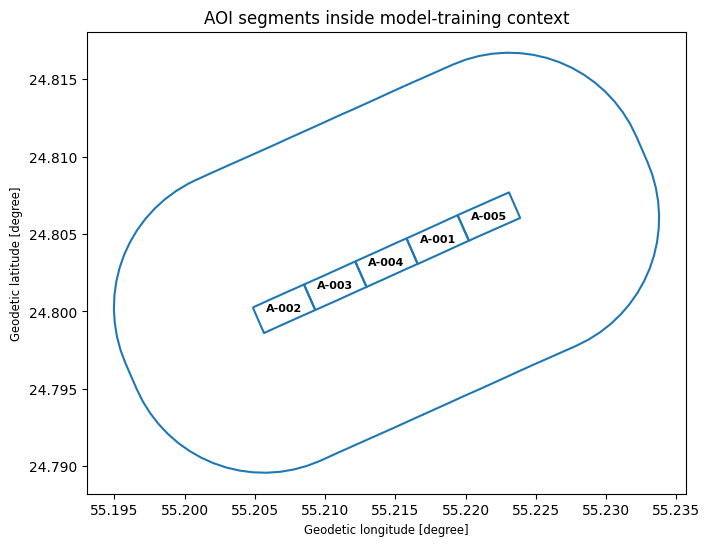

In [16]:
aoi = gpd.read_file(AOI_GEOJSON)
display(aoi)
print("AOI CRS:", aoi.crs)
print("AOI bounds:", aoi.total_bounds)
print("Supplied segments:", aoi["segment_id"].tolist())

# Wider model/study context
CONTEXT_GEOJSON = WORK_DIR / "analysis_context.geojson"
context = make_buffered_context(AOI_GEOJSON, CONTEXT_GEOJSON, CONTEXT_BUFFER_M)

# Independent reporting grid
planning_grid_metric = make_regular_grid(context, GRID_SIZE_M)
planning_grid = planning_grid_metric.to_crs(aoi.crs)

GRID_GEOJSON = WORK_DIR / "planning_grid.geojson"
planning_grid.to_file(GRID_GEOJSON, driver="GeoJSON")

print("Study buffer:", CONTEXT_BUFFER_M, "m")
print("Grid size:", GRID_SIZE_M, "m")
print("Planning cells:", len(planning_grid))

ax = context.boundary.plot(figsize=(10, 8), linewidth=2)
planning_grid.boundary.plot(ax=ax, linewidth=0.35, alpha=0.65)
aoi.boundary.plot(ax=ax, linewidth=2)

for _, row in aoi.iterrows():
    point = row.geometry.representative_point()
    ax.annotate(
        text=str(row["segment_id"]),
        xy=(point.x, point.y),
        ha="center",
        va="center",
        fontsize=8,
        fontweight="bold"
    )

ax.set_title("Broader study context + 250 m planning grid + supplied AOI reference")
plt.show()

## 4. Sentinel-2 discovery, scaling and 10 m alignment


In [17]:
s2_paths = {
    "B02": find_one(S2_ROOT, "*_B02_10m.tif"),
    "B03": find_one(S2_ROOT, "*_B03_10m.tif"),
    "B04": find_one(S2_ROOT, "*_B04_10m.tif"),
    "B08": find_one(S2_ROOT, "*_B08_10m.tif"),
    "B11": find_one(S2_ROOT, "*_B11_20m.tif"),
    "B12": find_one(S2_ROOT, "*_B12_20m.tif"),
    "SCL": find_one(S2_ROOT, "*_SCL_20m.tif"),
}
S2_MTD = find_one(S2_ROOT, "MTD_MSIL2A.xml")
for name, p in s2_paths.items(): print(name, raster_info(p))


def parse_s2_scaling(mtd_xml):
    root = ET.parse(mtd_xml).getroot()
    local = lambda tag: tag.split("}")[-1]
    quant=None; offsets={}; band_ids={}
    for e in root.iter():
        t=local(e.tag)
        if t=="BOA_QUANTIFICATION_VALUE": quant=float(e.text)
        elif t=="BOA_ADD_OFFSET": offsets[int(e.attrib["band_id"])]=float(e.text)
        elif t=="Spectral_Information": band_ids[e.attrib["physicalBand"]]=int(e.attrib["bandId"])
    return quant, offsets, band_ids

S2_QUANT, S2_OFFSETS, S2_BAND_IDS = parse_s2_scaling(S2_MTD)
print("Quantification:", S2_QUANT, "Offsets:", S2_OFFSETS)


def s2_to_reflectance(dn, band_name):
    print(S2_BAND_IDS)
    t = S2_BAND_IDS[band_name] if band_name in S2_BAND_IDS else S2_BAND_IDS[band_name.replace("0","")]
    offset = S2_OFFSETS[t]
    out = (dn.astype(np.float32) + offset) / S2_QUANT
    out[(dn==0) | (dn==65535)] = np.nan
    return out

S2_REF = WORK_DIR / "s2_B04_10m_context.tif"
warp_cutline(s2_paths["B04"], S2_REF, CONTEXT_GEOJSON, 10, 10, "bilinear", 0)
aligned_s2 = {"B04":S2_REF}
for b in ["B02","B03","B08","B11","B12"]:
    dst = WORK_DIR / f"s2_{b}_10m_context.tif"
    warp_like(s2_paths[b], S2_REF, dst, "bilinear", 0)
    aligned_s2[b]=dst
SCL_10M = WORK_DIR / "s2_SCL_10m_context.tif"
warp_like(s2_paths["SCL"], S2_REF, SCL_10M, "near", 0)
print(raster_info(S2_REF))


B02 {'width': 10980, 'height': 10980, 'bands': 1, 'dtype': 'UInt16', 'nodata': None, 'pixel_size_x': 10.0, 'pixel_size_y': -10.0, 'projection': 'PROJCS["WGS 84 / UTM zone 40N",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",57],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","32640"]]'}
B03 {'width': 10980, 'height': 10980, 'bands': 1, 'dtype': 'UInt16', 'nodata': None, 'pixel_size_x': 10.0, 'pixel_size_y': -10.0, 'projection': 'PROJCS["WGS 84 / UTM zone 40N",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHOR

## 5. Sentinel-2 spectral features


{'B1': 0, 'B2': 1, 'B3': 2, 'B4': 3, 'B5': 4, 'B6': 5, 'B7': 6, 'B8': 7, 'B8A': 8, 'B9': 9, 'B10': 10, 'B11': 11, 'B12': 12}
{'B1': 0, 'B2': 1, 'B3': 2, 'B4': 3, 'B5': 4, 'B6': 5, 'B7': 6, 'B8': 7, 'B8A': 8, 'B9': 9, 'B10': 10, 'B11': 11, 'B12': 12}
{'B1': 0, 'B2': 1, 'B3': 2, 'B4': 3, 'B5': 4, 'B6': 5, 'B7': 6, 'B8': 7, 'B8A': 8, 'B9': 9, 'B10': 10, 'B11': 11, 'B12': 12}
{'B1': 0, 'B2': 1, 'B3': 2, 'B4': 3, 'B5': 4, 'B6': 5, 'B7': 6, 'B8': 7, 'B8A': 8, 'B9': 9, 'B10': 10, 'B11': 11, 'B12': 12}
{'B1': 0, 'B2': 1, 'B3': 2, 'B4': 3, 'B5': 4, 'B6': 5, 'B7': 6, 'B8': 7, 'B8A': 8, 'B9': 9, 'B10': 10, 'B11': 11, 'B12': 12}
{'B1': 0, 'B2': 1, 'B3': 2, 'B4': 3, 'B5': 4, 'B6': 5, 'B7': 6, 'B8': 7, 'B8A': 8, 'B9': 9, 'B10': 10, 'B11': 11, 'B12': 12}
Valid Sentinel-2 pixels: 79804 / 118200


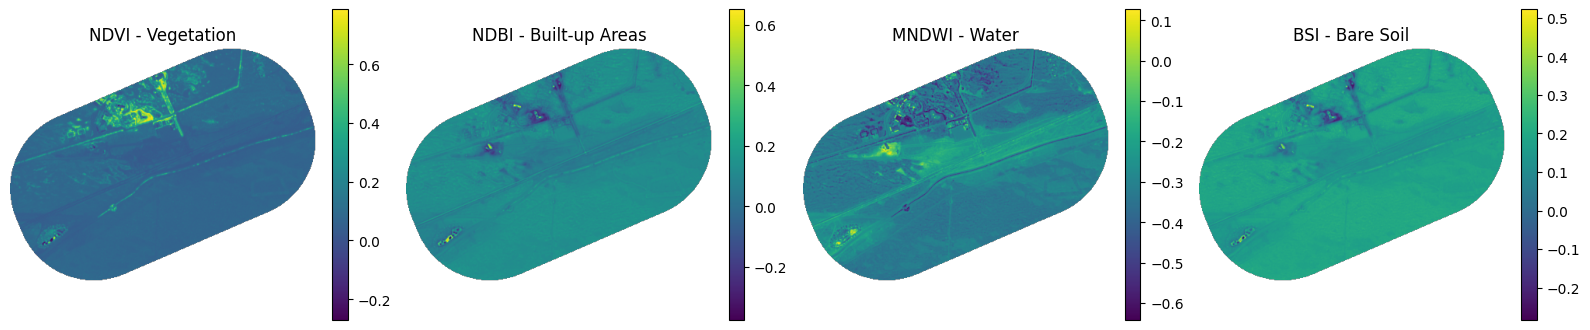

In [18]:
B={}
for b in ["B02","B03","B04","B08","B11","B12"]:
    B[b]=s2_to_reflectance(read_array(aligned_s2[b], np.uint16), b)
scl=read_array(SCL_10M, np.uint8)
bad_scl=np.isin(scl,[0,1,2,3,8,9,10,11])

NDVI=safe_ratio(B["B08"]-B["B04"], B["B08"]+B["B04"])
NDBI=safe_ratio(B["B11"]-B["B08"], B["B11"]+B["B08"])
MNDWI=safe_ratio(B["B03"]-B["B11"], B["B03"]+B["B11"])
BSI=safe_ratio((B["B11"]+B["B04"])-(B["B08"]+B["B02"]),
               (B["B11"]+B["B04"])+(B["B08"]+B["B02"]))
feature_10m={**B,"NDVI":NDVI,"NDBI":NDBI,"MNDWI":MNDWI,"BSI":BSI}
valid_s2=~bad_scl
for arr in feature_10m.values(): valid_s2 &= np.isfinite(arr)
print("Valid Sentinel-2 pixels:",valid_s2.sum(),"/",valid_s2.size)

fig,axes=plt.subplots(1,4,figsize=(16,4))
for ax, (name, arr) in zip(axes, [
    ("NDVI - Vegetation", NDVI),
    ("NDBI - Built-up Areas", NDBI),
    ("MNDWI - Water", MNDWI),
    ("BSI - Bare Soil", BSI)
]):
    #vmin=-1,vmax=1
    im=ax.imshow(np.where(valid_s2,arr,np.nan)); ax.set_title(name); ax.axis("off"); plt.colorbar(im,ax=ax,fraction=.046)
plt.tight_layout(); plt.show()


## 6. Unsupervised surface-regime clustering


,B02,B03,B04,B08,B11,B12,NDVI,NDBI,MNDWI,BSI,pixel_count
cluster,,,,,,,,,,,
0,0.276208,0.364761,0.447406,0.496633,0.555353,0.451881,0.052541,0.055292,-0.206911,0.129324,6255
1,0.226235,0.311764,0.396296,0.455571,0.562294,0.478823,0.069733,0.104334,-0.286061,0.168456,23141
2,0.094318,0.144075,0.159083,0.358310,0.359518,0.265872,0.388327,0.000174,-0.425287,0.063440,3684
3,0.181371,0.246305,0.297552,0.370790,0.421157,0.331407,0.110310,0.065419,-0.260853,0.132535,9466
4,0.191106,0.270276,0.350062,0.419314,0.549457,0.463805,0.091021,0.134309,-0.341104,0.191342,37258


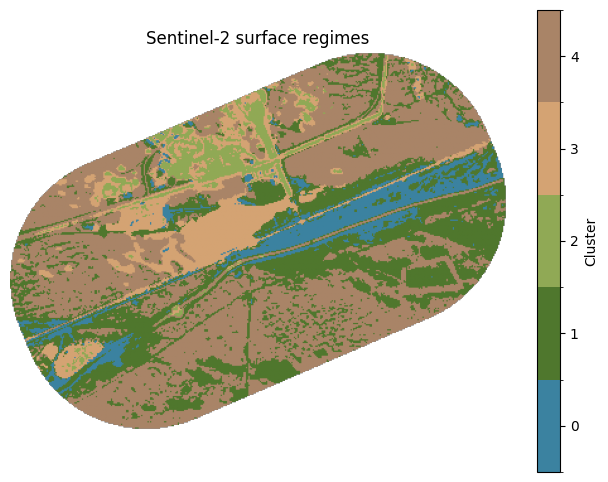

Suggested vegetation-like cluster: 2
Suggested water-like cluster: 0
Inspect these visually and override if necessary.


In [78]:
cluster_features=["B02","B03","B04","B08","B11","B12","NDVI","NDBI","MNDWI","BSI"]
X_all=np.column_stack([feature_10m[n][valid_s2] for n in cluster_features])
if len(X_all)>MAX_CLUSTER_TRAIN_PIXELS:
    rng=np.random.default_rng(RANDOM_STATE); idx=rng.choice(len(X_all),MAX_CLUSTER_TRAIN_PIXELS,replace=False); X_fit=X_all[idx]
else: X_fit=X_all
scaler=StandardScaler().fit(X_fit)
cluster_model=MiniBatchKMeans(n_clusters=N_CLUSTERS,batch_size=4096,n_init="auto",random_state=RANDOM_STATE)
cluster_model.fit(scaler.transform(X_fit))
labels=cluster_model.predict(scaler.transform(X_all))
cluster_map=np.full(valid_s2.shape,-1,dtype=np.int16); cluster_map[valid_s2]=labels
profile=pd.DataFrame(X_all,columns=cluster_features); profile["cluster"]=labels
cluster_profile=profile.groupby("cluster")[cluster_features].mean(); cluster_profile["pixel_count"]=profile.groupby("cluster").size()
display(cluster_profile)

from matplotlib.colors import BoundaryNorm
import matplotlib.pyplot as plt

from matplotlib.colors import ListedColormap, BoundaryNorm

cluster_colors = [
    "#3B82A0",  # water blue
    "#4F772D",  # vegetation green
    "#90A955",  # light vegetation
    "#D4A373",  # soil
    "#A98467",  # dry/bare land
]

cmap = ListedColormap(cluster_colors[:N_CLUSTERS])

norm = BoundaryNorm(
    np.arange(-0.5, N_CLUSTERS + 0.5, 1),
    N_CLUSTERS
)

plt.figure(figsize=(8, 6))

im = plt.imshow(
    np.where(cluster_map >= 0, cluster_map, np.nan),
    cmap=cmap,
    norm=norm
)

plt.title("Sentinel-2 surface regimes")
plt.axis("off")

cbar = plt.colorbar(
    im,
    ticks=np.arange(N_CLUSTERS),
    boundaries=np.arange(-0.5, N_CLUSTERS + 0.5, 1)
)

cbar.set_label("Cluster")
plt.show()


CLUSTER_TIF=OUTPUT_DIR/"s2_surface_regimes_10m.tif"
write_geotiff(CLUSTER_TIF,cluster_map,S2_REF,nodata=-1,gdal_type=gdal.GDT_Int16)

VEGETATION_CLUSTER=int(cluster_profile["NDVI"].idxmax())
WATER_CLUSTER=int(cluster_profile["MNDWI"].idxmax())
print("Suggested vegetation-like cluster:",VEGETATION_CLUSTER)
print("Suggested water-like cluster:",WATER_CLUSTER)
print("Inspect these visually and override if necessary.")


The remaining clusters are deliberately called **surface regimes**, not automatically “built-up” or “impervious.” In the UAE, bare soil, sand, construction land and built surfaces can be spectrally confused.


## 7. Landsat LST and QA


ST scale/offset: 0.00341802 149.0
LST min/median/max: 48.5318 58.338104 61.721954


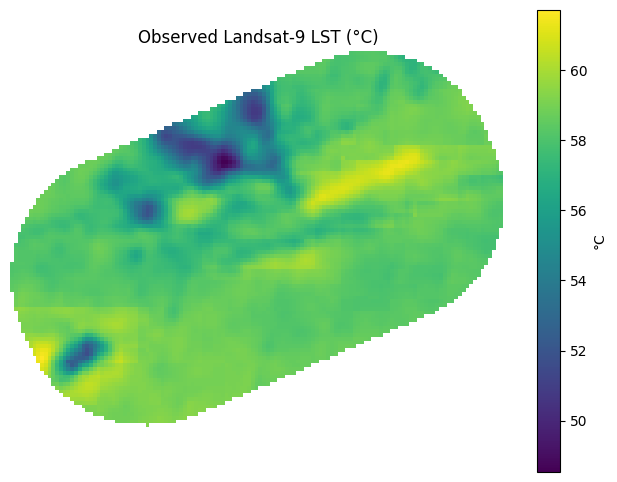

PosixPath('outputs/landsat_lst_celsius_30m.tif')

In [56]:
ls_paths={
    "ST_B10":find_one(LANDSAT_ROOT,"*_ST_B10.TIF"),
    "QA_PIXEL":find_one(LANDSAT_ROOT,"*_QA_PIXEL.TIF"),
    "QA_RADSAT":find_one(LANDSAT_ROOT,"*_QA_RADSAT.TIF"),
}
LANDSAT_MTL=find_one(LANDSAT_ROOT,"*_MTL.xml")
root=ET.parse(LANDSAT_MTL).getroot()
val=lambda tag: root.find(f".//{tag}").text
ST_MULT=float(val("TEMPERATURE_MULT_BAND_ST_B10")); ST_ADD=float(val("TEMPERATURE_ADD_BAND_ST_B10"))
print("ST scale/offset:",ST_MULT,ST_ADD)

LST_RAW=WORK_DIR/"landsat_ST_B10_context.tif"; QA_PIXEL=WORK_DIR/"landsat_QA_PIXEL_context.tif"; QA_RADSAT=WORK_DIR/"landsat_QA_RADSAT_context.tif"
warp_cutline(ls_paths["ST_B10"],LST_RAW,CONTEXT_GEOJSON,30,30,"near",0)
warp_like(ls_paths["QA_PIXEL"],LST_RAW,QA_PIXEL,"near",0)
warp_like(ls_paths["QA_RADSAT"],LST_RAW,QA_RADSAT,"near",0)
st_dn=read_array(LST_RAW,np.uint16); qa=read_array(QA_PIXEL,np.uint16); qasat=read_array(QA_RADSAT,np.uint16)
clear=np.ones_like(qa,dtype=bool)
for bit in [0,1,2,3,4,5]: clear &= ((qa>>bit)&1)==0
clear &= (qasat==0) & (st_dn!=0)
lst_c=st_dn.astype(np.float32)*ST_MULT+ST_ADD-273.15
lst_c[~clear]=np.nan
print("LST min/median/max:",np.nanmin(lst_c),np.nanmedian(lst_c),np.nanmax(lst_c))
plt.figure(figsize=(8,6)); im=plt.imshow(lst_c); plt.title("Observed Landsat-9 LST (°C)"); plt.axis("off"); plt.colorbar(im,label="°C"); plt.show()
LST_C_TIF=OUTPUT_DIR/"landsat_lst_celsius_30m.tif"; write_geotiff(LST_C_TIF,lst_c,LST_RAW)


## 7A. Larger-area visual check: Sentinel‑2 true colour alongside Landsat LST

Before interpreting any model, inspect the actual surface context. The left panel uses Sentinel‑2 B04/B03/B02; the right panel shows the observed Landsat LST for the same broader study context.

This is specifically intended to prevent the original supplied AOI geometry from dictating what the PoC studies.

In [ ]:
def contrast_stretch(channel, valid_mask, low=2, high=98):
    vals = channel[valid_mask & np.isfinite(channel)]
    if len(vals) == 0:
        return np.zeros_like(channel, dtype=np.float32)
    lo, hi = np.percentile(vals, [low, high])
    if hi <= lo:
        return np.zeros_like(channel, dtype=np.float32)
    out = (channel - lo) / (hi - lo)
    return np.clip(out, 0, 1)

rgb = np.dstack([
    contrast_stretch(B["B04"], valid_s2),
    contrast_stretch(B["B03"], valid_s2),
    contrast_stretch(B["B02"], valid_s2),
])
rgb[~valid_s2] = np.nan

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

axes[0].imshow(rgb)
axes[0].set_title("Sentinel-2 true colour — broader study context")
axes[0].axis("off")

im = axes[1].imshow(lst_c)
axes[1].set_title("Landsat-9 observed LST (°C)")
axes[1].axis("off")
plt.colorbar(im, ax=axes[1], fraction=0.046, label="°C")

plt.tight_layout()
plt.show()

`ST_B10` is already the Level-2 surface-temperature product. The notebook only applies the product metadata scale/offset and QA masking; it does not reimplement the thermal retrieval from radiance.


## 8. Aggregate Sentinel-2 features to the Landsat 30 m grid


In [57]:
feature_10m_paths={}
for name,arr in feature_10m.items():
    x=arr.astype(np.float32).copy(); x[~valid_s2]=np.nan
    p=WORK_DIR/f"{name}_10m.tif"; write_geotiff(p,x,S2_REF); feature_10m_paths[name]=p
feature_30m={}
for name,src in feature_10m_paths.items():
    dst=WORK_DIR/f"{name}_30m.tif"; warp_like(src,LST_RAW,dst,"average",None); feature_30m[name]=read_array(dst)
print("Sentinel-2 30 m shape:",next(iter(feature_30m.values())).shape,"LST shape:",lst_c.shape)

cluster_fraction_30m={}
for k in range(N_CLUSTERS):
    one=np.where(valid_s2,(cluster_map==k).astype(np.float32),np.nan)
    src=WORK_DIR/f"cluster_{k}_onehot_10m.tif"; dst=WORK_DIR/f"cluster_{k}_fraction_30m.tif"
    write_geotiff(src,one,S2_REF); warp_like(src,LST_RAW,dst,"average",None); cluster_fraction_30m[k]=read_array(dst)
stack=np.stack([cluster_fraction_30m[k] for k in range(N_CLUSTERS)],axis=-1)
all_nan=np.all(~np.isfinite(stack),axis=-1); safe=np.where(np.isfinite(stack),stack,-np.inf)
dominant=np.argmax(safe,axis=-1).astype(np.int16); dominant[all_nan]=-1
rows=[]
for k in range(N_CLUSTERS):
    m=(dominant==k)&np.isfinite(lst_c)
    rows.append({"cluster":k,"mean_LST_C":float(np.nanmean(lst_c[m])) if m.any() else np.nan,"cells":int(m.sum())})
cluster_lst=pd.DataFrame(rows).set_index("cluster"); display(cluster_lst)
HEAT_ASSOCIATED_CLUSTER=int(cluster_lst["mean_LST_C"].idxmax())
print("Surface regime most associated with higher observed LST:",HEAT_ASSOCIATED_CLUSTER)


Sentinel-2 30 m shape: (101, 132) LST shape: (101, 132)


,mean_LST_C,cells
cluster,,
0,57.917896,2042
1,53.764214,421
2,58.548923,1556
3,58.570957,4142
4,56.209103,528


Surface regime most associated with higher observed LST: 3


## 9. Supervised model: Sentinel-2 → Landsat LST


Train/Test: 6464 2225
Spatial holdout MAE: 0.6450751586640507
Spatial holdout RMSE: 0.9016806183034406
Spatial holdout R2: 0.7631640415705079


,importance
B11,0.231954
B12,0.189853
BSI,0.132151
B04,0.103722
NDBI,0.079425
NDVI,0.076392
B03,0.060502
B02,0.054318
MNDWI,0.037808
B08,0.033876


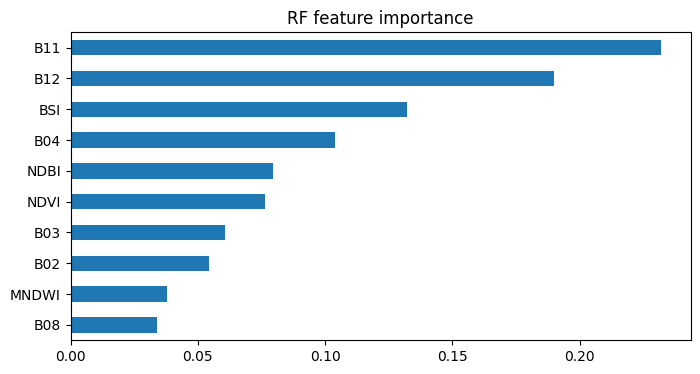

In [58]:
reg_features=["B02","B03","B04","B08","B11","B12","NDVI","NDBI","MNDWI","BSI"]
valid_ml=np.isfinite(lst_c)
for n in reg_features: valid_ml &= np.isfinite(feature_30m[n])
r,c=np.where(valid_ml)
X=np.column_stack([feature_30m[n][valid_ml] for n in reg_features]); y=lst_c[valid_ml]
ref=gdal.Open(str(LST_RAW)); px=abs(ref.GetGeoTransform()[1]); block_px=max(1,int(round(SPATIAL_BLOCK_M/px)))
groups=(r//block_px).astype(np.int64)*1_000_000+(c//block_px).astype(np.int64)
split=GroupShuffleSplit(n_splits=1,test_size=.25,random_state=RANDOM_STATE)
train_idx,test_idx=next(split.split(X,y,groups=groups))
model=RandomForestRegressor(n_estimators=400,max_depth=14,min_samples_leaf=3,max_features="sqrt",n_jobs=-1,random_state=RANDOM_STATE)
model.fit(X[train_idx],y[train_idx]); pred_test=model.predict(X[test_idx])
print("Train/Test:",len(train_idx),len(test_idx))
print("Spatial holdout MAE:",mean_absolute_error(y[test_idx],pred_test))
print("Spatial holdout RMSE:",mean_squared_error(y[test_idx],pred_test)**0.5)
print("Spatial holdout R2:",r2_score(y[test_idx],pred_test))
importance=pd.Series(model.feature_importances_,index=reg_features).sort_values(ascending=False)
display(importance.to_frame("importance"))
importance.sort_values().plot(kind="barh",figsize=(8,4),title="RF feature importance"); plt.show()


The split is spatial rather than random because neighboring pixels are correlated. Feature importance is associational, not causal.


## 10. Predict LST across the context and inspect residuals


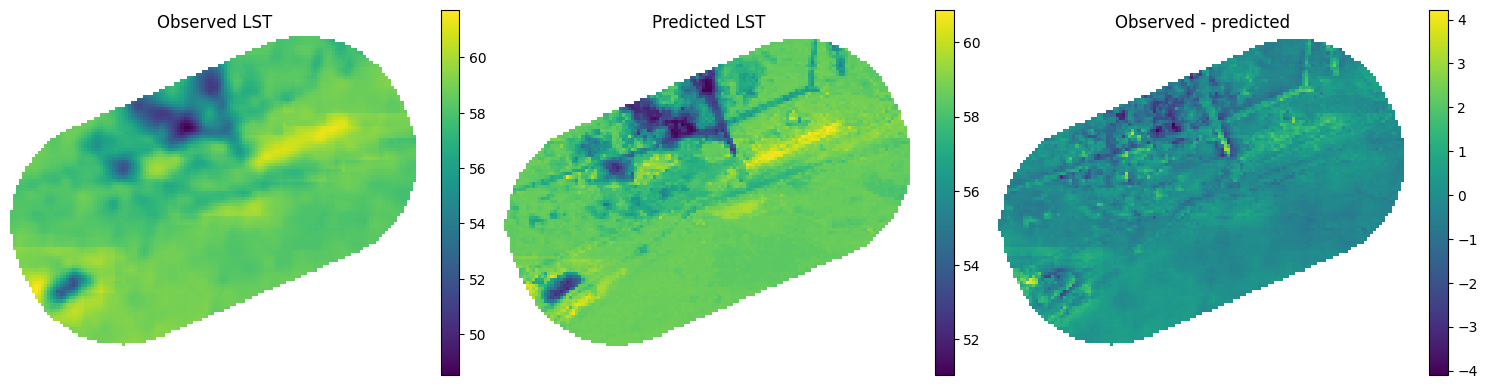

In [59]:
valid_pred=np.ones_like(lst_c,dtype=bool)
for n in reg_features: valid_pred &= np.isfinite(feature_30m[n])
Xp=np.column_stack([feature_30m[n][valid_pred] for n in reg_features])
pred_lst=np.full_like(lst_c,np.nan,dtype=np.float32); pred_lst[valid_pred]=model.predict(Xp).astype(np.float32)
residual=lst_c-pred_lst
write_geotiff(OUTPUT_DIR/"predicted_lst_from_sentinel2_30m.tif",pred_lst,LST_RAW)
write_geotiff(OUTPUT_DIR/"lst_model_residual_30m.tif",residual,LST_RAW)
fig,axes=plt.subplots(1,3,figsize=(15,4))
for ax,title,arr in [(axes[0],"Observed LST",lst_c),(axes[1],"Predicted LST",pred_lst),(axes[2],"Observed - predicted",residual)]:
    im=ax.imshow(arr); ax.set_title(title); ax.axis("off"); plt.colorbar(im,ax=ax,fraction=.046)
plt.tight_layout(); plt.show()


The predicted layer remains a **30 m statistical product**. It is not a new physical thermal observation and should not be presented as true 10 m temperature.


## 11. Convert clusters + LST model outputs into grid-level Urban Planning indicators

This is where the two analysis modes meet:

- **Clustering** tells us the surface-regime composition of each planning cell at Sentinel‑2 resolution.
- **Observed Landsat LST** tells us how hot the cell actually was during the acquisition.
- **The supervised LST model** tells us how well those Sentinel‑2 surface characteristics explain the thermal pattern.

Each 250 m grid cell becomes a compact Urban Planning object.

In [60]:
# Prepare the regular planning grid in each raster CRS.
s2_crs = gdal.Open(str(S2_REF)).GetProjection()
ls_crs = gdal.Open(str(LST_RAW)).GetProjection()

grid_s2 = planning_grid.to_crs(s2_crs)
grid_ls = planning_grid.to_crs(ls_crs)

GRID_S2 = WORK_DIR / "planning_grid_s2.geojson"
GRID_LS = WORK_DIR / "planning_grid_landsat.geojson"
grid_s2.to_file(GRID_S2, driver="GeoJSON")
grid_ls.to_file(GRID_LS, driver="GeoJSON")

context_lst = lst_c[np.isfinite(lst_c)]
hot_threshold = float(np.nanpercentile(context_lst, 85))
print("Study-context 85th percentile LST:", hot_threshold, "°C")

indicator_rows = []

for gid in planning_grid["grid_id"]:
    m10 = rasterize_feature_mask(GRID_S2, S2_REF, "grid_id", gid)
    m30 = rasterize_feature_mask(GRID_LS, LST_RAW, "grid_id", gid)

    # Observation coverage / quality
    s2_total = int(m10.sum())
    lst_total = int(m30.sum())

    v10 = m10 & valid_s2
    v30 = m30 & np.isfinite(lst_c)

    s2_valid_fraction = v10.sum() / s2_total if s2_total else np.nan
    lst_valid_fraction = v30.sum() / lst_total if lst_total else np.nan

    # Skip cells with too little valid EO support.
    if (
        not np.isfinite(s2_valid_fraction)
        or not np.isfinite(lst_valid_fraction)
        or s2_valid_fraction < MIN_VALID_S2_FRACTION
        or lst_valid_fraction < MIN_VALID_LST_FRACTION
    ):
        continue

    # --- Cluster composition at 10 m ---
    cluster_fracs = {
        k: float(np.mean(cluster_map[v10] == k))
        for k in range(N_CLUSTERS)
    }

    dominant_cluster = max(cluster_fracs, key=cluster_fracs.get)
    dominant_cluster_fraction = cluster_fracs[dominant_cluster]

    vegetation_frac = cluster_fracs.get(VEGETATION_CLUSTER, np.nan)
    water_frac = cluster_fracs.get(WATER_CLUSTER, np.nan)
    heat_surface_frac = cluster_fracs.get(HEAT_ASSOCIATED_CLUSTER, np.nan)

    # Spectral context
    mean_ndvi = float(np.nanmean(NDVI[v10]))
    mean_ndbi = float(np.nanmean(NDBI[v10]))
    mean_bsi = float(np.nanmean(BSI[v10]))

    # --- Observed thermal indicators at 30 m ---
    mean_lst = float(np.nanmean(lst_c[v30]))
    median_lst = float(np.nanmedian(lst_c[v30]))
    p90_lst = float(np.nanpercentile(lst_c[v30], 90))
    hot_frac = float(np.mean(lst_c[v30] >= hot_threshold))

    # --- Supervised model outputs ---
    p_mask = m30 & np.isfinite(pred_lst)
    r_mask = m30 & np.isfinite(residual)

    mean_pred = float(np.nanmean(pred_lst[p_mask])) if p_mask.any() else np.nan
    mean_resid = float(np.nanmean(residual[r_mask])) if r_mask.any() else np.nan

    # --- Planning interpretation ---
    thermal_pressure = percentile_rank(context_lst, mean_lst)
    vegetation_deficit = 1.0 - vegetation_frac if np.isfinite(vegetation_frac) else np.nan

    # Transparent prototype ranking, not a validated risk score.
    priority = np.nan
    if all(np.isfinite(x) for x in [thermal_pressure, vegetation_deficit, heat_surface_frac]):
        priority = 100 * (
            0.50 * thermal_pressure
            + 0.30 * vegetation_deficit
            + 0.20 * heat_surface_frac
        )

    row = {
        "grid_id": gid,
        "s2_valid_fraction": s2_valid_fraction,
        "lst_valid_fraction": lst_valid_fraction,

        "mean_lst_c": mean_lst,
        "median_lst_c": median_lst,
        "p90_lst_c": p90_lst,
        "hot_area_fraction": hot_frac,
        "thermal_pressure_pct": 100 * thermal_pressure,

        "mean_pred_lst_c": mean_pred,
        "mean_model_residual_c": mean_resid,

        "mean_ndvi": mean_ndvi,
        "mean_ndbi": mean_ndbi,
        "mean_bsi": mean_bsi,

        "vegetation_like_fraction": vegetation_frac,
        "water_like_fraction": water_frac,
        "heat_assoc_surface_fraction": heat_surface_frac,

        "dominant_cluster": int(dominant_cluster),
        "dominant_cluster_fraction": dominant_cluster_fraction,

        "planning_priority_score": priority,
    }

    # Keep the complete cluster composition so the UI can explain each cell.
    for k, frac in cluster_fracs.items():
        row[f"cluster_{k}_fraction"] = frac

    indicator_rows.append(row)

grid_indicators = (
    pd.DataFrame(indicator_rows)
      .sort_values("planning_priority_score", ascending=False)
      .reset_index(drop=True)
)

print("Usable planning cells:", len(grid_indicators), "/", len(planning_grid))
display(grid_indicators.head(20))

Context 85th percentile LST: 59.096893310546875 °C


,segment_id,mean_lst_c,p90_lst_c,hot_area_fraction,thermal_pressure_pct,mean_pred_lst_c,mean_model_residual_c,mean_ndvi,vegetation_like_fraction,water_like_fraction,heat_assoc_surface_fraction,planning_priority_score
4,A-005,59.258568,60.588493,0.544444,89.679675,59.149311,0.109257,0.065560,0.000000,0.018610,0.133995,77.519738
0,A-001,58.433617,59.823212,0.200000,55.819986,58.549870,-0.116254,0.054064,0.000000,0.021040,0.038366,58.677320
1,A-002,57.784836,58.167206,0.000000,24.328897,58.060337,-0.275499,0.084243,0.000000,0.068069,0.372525,49.614944
2,A-003,57.823597,58.217793,0.000000,25.287616,57.851372,-0.027777,0.074534,0.001236,0.457355,0.144623,45.499185
3,A-004,57.775658,58.300507,0.000000,24.148432,58.050694,-0.275028,0.059586,0.001236,0.291718,0.012361,42.284352


### How to interpret one planning cell

A cell now answers both **surface** and **thermal** questions:

- `cluster_*_fraction`: percentage of the cell occupied by each discovered Sentinel‑2 surface regime.
- `vegetation_like_fraction`: percentage belonging to the most vegetation-like cluster.
- `dominant_cluster`: the most common surface regime in the cell.
- `mean_lst_c` / `p90_lst_c`: observed Landsat surface temperature statistics.
- `hot_area_fraction`: fraction of valid Landsat cells above the broader study area's 85th-percentile LST.
- `thermal_pressure_pct`: percentile rank of the cell's mean LST within the study context.
- `mean_pred_lst_c`: LST predicted from Sentinel‑2 surface characteristics.
- `mean_model_residual_c`: observed minus predicted LST. Positive values indicate the cell was hotter than the Sentinel‑2 model expected.
- `planning_priority_score`: transparent prototype ranking combining thermal pressure, vegetation deficit, and the fraction of the surface regime most associated with higher LST.

The score is a **PoC prioritization heuristic**, not a validated risk score or causal recommendation.

## 12. Export the planning grid + indicators

In [ ]:
grid_result = planning_grid.merge(grid_indicators, on="grid_id", how="inner")

OUT_GRID_GEOJSON = OUTPUT_DIR / "urban_planning_grid_indicators.geojson"
OUT_GRID_CSV = OUTPUT_DIR / "urban_planning_grid_indicators.csv"

grid_result.to_file(OUT_GRID_GEOJSON, driver="GeoJSON")
grid_indicators.to_csv(OUT_GRID_CSV, index=False)

print("Saved:", OUT_GRID_GEOJSON)
print("Saved:", OUT_GRID_CSV)

display(
    grid_result[
        [
            "grid_id",
            "mean_lst_c",
            "p90_lst_c",
            "vegetation_like_fraction",
            "dominant_cluster",
            "heat_assoc_surface_fraction",
            "thermal_pressure_pct",
            "planning_priority_score",
        ]
    ].sort_values("planning_priority_score", ascending=False).head(20)
)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

grid_result.plot(
    ax=axes[0],
    column="planning_priority_score",
    legend=True,
    edgecolor="black",
    linewidth=0.25,
)
axes[0].set_title("Planning priority by 250 m cell")
axes[0].set_axis_off()

grid_result.plot(
    ax=axes[1],
    column="vegetation_like_fraction",
    legend=True,
    edgecolor="black",
    linewidth=0.25,
)
axes[1].set_title("Vegetation-like fraction by 250 m cell")
axes[1].set_axis_off()

plt.tight_layout()
plt.show()

## 13. Before presenting the PoC

- Verify cluster interpretation visually; cluster IDs are discovered regimes, not automatically land-cover labels.
- Compare the cluster map with the 250 m planning grid: the cluster map explains **what surfaces exist**, while the grid explains **what each geographic planning unit looks like overall**.
- Report LST regression MAE/RMSE/R² from the spatial holdout.
- Check grid cells have sufficient valid Sentinel‑2 and Landsat support.
- Keep observed LST distinct from predicted LST.
- Do not claim the 30 m Landsat grid is true 30 m thermal physics.
- Do not claim causal effects from feature importance or LST associations.
- Label the planning-priority score as a transparent prototype heuristic.
- Keep the supplied `A-001 ... A-005` polygons as reference only unless the organizers explain their intended semantic meaning.
- Export sensor/product IDs, acquisition dates, model version and preprocessing version with the final ManzelTwin layer.